# 06 · Final submission: blending, balancing and the sentiment shift

Our best single models were k-NN for images (notebook 02) and the neural network for sentiment (notebook 03), which together scored **0.627** on Kaggle. This notebook explains the four steps that took the final submission to **0.651**, and one step that did not work.

Everything here uses `scripts/make_blend_submission.py`, which builds the final submission:

```bash
uv run python scripts/make_blend_submission.py --name final --balance-image --recenter-sentiment-test --sentiment-seeds 5
```

Two of the steps (image balancing and sentiment re-centring) use statistics of the whole **unlabelled** test set. No test labels are used at any point; section 5 discusses this.

In [1]:
import sys
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import cross_val_score

sys.path.insert(0, "../scripts")
import make_blend_submission as mbs
from comp472_project.config import FIGURES_DIR, ROOT, SENTIMENT_LABELS, seed_everything
from comp472_project.data import load_split, load_test, load_train
from comp472_project.preprocessing import SqrtTransform, Standardizer

seed_everything()

## 1. Every Kaggle submission

Validation accuracy is on our fixed 80/20 split; the public score is Kaggle's leaderboard (2,500 test rows per task). Model choices were made on validation; the public score was only used to check each step.

In [2]:
log = pd.read_csv(ROOT / "submissions" / "log.csv")
log["name"] = log["file"].str.replace(r"^\d{8}-\d{6}_|\.csv$", "", regex=True)
log[["name", "image_val_acc", "sentiment_val_acc", "mean_val_acc", "public_score"]].dropna(subset=["public_score"])

,name,image_val_acc,sentiment_val_acc,mean_val_acc,public_score
0,knn,0.5192,0.5896,NaN,0.576
2,knn_image_nn_sentiment_v1,0.5627,0.6792,0.6210,0.627
4,blend_v1,0.5790,0.6792,0.6291,0.633
5,blend_bal_v1,0.5860,0.6792,0.6326,0.639
6,blend_bal_prior_v1,0.5860,NaN,NaN,0.631
7,blend_bal_recenter_v1,0.5860,0.6792,0.6326,0.649
8,blend_bal_recenter_ens5_v1,0.5860,0.6750,0.6305,0.651


## 2. Images: blending k-NN with the neural network

k-NN scores each class by the mean cosine similarity of the 3 most similar training images of that class (square-rooted and standardised features). These scores are turned into probabilities and mixed with the tuned network's probabilities: 80% k-NN, 20% network, chosen on the validation split. The network is much weaker on its own (38.7%), but it makes different mistakes, so a small share of its vote fixes some k-NN errors. This cell trains the network once (≈1.5 min).

In [3]:
img = load_split("image")
sq_std = [SqrtTransform(), Standardizer()]
A, B = img.X_train, img.X_val
for t in sq_std:
    A = t.fit_transform(A, img.y_train)
    B = t.transform(B)
classes = np.unique(img.y_train)
sim = mbs._unit(B) @ mbs._unit(A).T
score = np.stack([np.sort(sim[:, img.y_train == c], axis=1)[:, -mbs.KNN_TOP:].mean(1) for c in classes], axis=1)
p_knn = np.exp((score - score.max(1, keepdims=True)) / mbs.KNN_TEMPERATURE)
p_knn /= p_knn.sum(1, keepdims=True)
seed_everything()
p_nn = mbs._nn("image").fit(A, img.y_train).predict_proba(B)

rows = []
for w in [0.0, 0.1, 0.2, 0.3, 0.4, 1.0]:
    p = (1 - w) * p_knn + w * p_nn
    rows.append({"network weight": w, "val accuracy": np.mean(classes[p.argmax(1)] == img.y_val)})
pd.DataFrame(rows).style.format({"val accuracy": "{:.4f}"}).hide(axis="index")

network weight,val accuracy
0.000000,0.5615
0.100000,0.5743
0.200000,0.5790
0.300000,0.5715
0.400000,0.5555
1.000000,0.3875


A network weight of 0.2 gives the best validation accuracy; more than that and the weaker model starts overriding correct k-NN answers.

## 3. Images: exactly 100 predictions per class

The project description states the image test set has exactly 100 images per class (and our validation split has exactly 80). The blended model does not respect this: some classes are predicted far more often than others. We assign labels so that every class gets exactly its share, choosing the assignment with the highest total log-probability (the Hungarian algorithm, `scipy.optimize.linear_sum_assignment`).

plain:    0.5790 accuracy, predictions per class 51-151
balanced: 0.5860 accuracy, predictions per class all 80


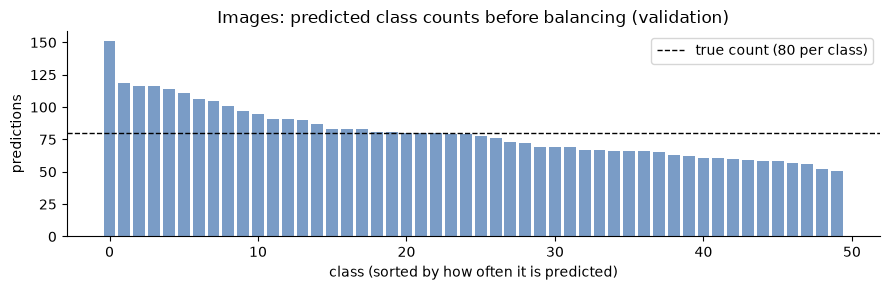

In [4]:
p_blend = (1 - mbs.NN_WEIGHT) * p_knn + mbs.NN_WEIGHT * p_nn
plain = classes[p_blend.argmax(1)]
balanced = mbs.balanced_labels(p_blend, classes, per_class=80)
counts = np.bincount(plain, minlength=50)
print(f"plain:    {np.mean(plain == img.y_val):.4f} accuracy, predictions per class {counts.min()}-{counts.max()}")
print(f"balanced: {np.mean(balanced == img.y_val):.4f} accuracy, predictions per class all {np.bincount(balanced).min()}")

fig, ax = plt.subplots(figsize=(9, 3))
ax.bar(range(50), np.sort(counts)[::-1], color="#7a9cc6")
ax.axhline(80, color="black", lw=1, ls="--", label="true count (80 per class)")
ax.set(xlabel="class (sorted by how often it is predicted)", ylabel="predictions", title="Images: predicted class counts before balancing (validation)")
ax.legend(); ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout(); plt.savefig(FIGURES_DIR / "final_image_class_counts.png", dpi=130); plt.show()

Balancing moves the over-predicted classes' least confident predictions to under-predicted classes. On Kaggle it raised the score from 0.633 to **0.639**.

## 4. Sentiment: the test set is shifted, and re-centring fixes it

Notebook 01 found that a linear classifier can tell training tweets from test tweets. Here we measure it again, then test the simplest possible explanation: that the whole test set is offset by a constant vector in embedding space. If so, centring each set on its own mean should make them indistinguishable.

In [5]:
_, X, y = load_train("sentiment")
_, T = load_test("sentiment")
rng = np.random.default_rng(0)
Xs = X[rng.choice(len(X), len(T), replace=False)]  # same size as the test set

def domain_auc(train_part, test_part):
    Z = np.vstack([train_part, test_part])
    is_test = np.r_[np.zeros(len(train_part)), np.ones(len(test_part))]
    return cross_val_score(LogisticRegression(max_iter=2000), Z, is_test, cv=3, scoring="roc_auc").mean()

s = Standardizer().fit(X)
auc_before = domain_auc(s.transform(Xs), s.transform(T))
auc_after = domain_auc(Xs - X.mean(0), T - T.mean(0))
print(f"train vs. test AUC, shared standardisation: {auc_before:.3f}")
print(f"train vs. test AUC, each set centred on its own mean: {auc_after:.3f}  (0.5 = indistinguishable)")
shift = np.linalg.norm(X.mean(0) - T.mean(0)) / np.sqrt((X.std(0) ** 2).sum())
print(f"size of the mean offset: {shift:.2f} x the typical spread of the training data")

train vs. test AUC, shared standardisation: 0.950
train vs. test AUC, each set centred on its own mean: 0.388  (0.5 = indistinguishable)
size of the mean offset: 0.26 x the typical spread of the training data


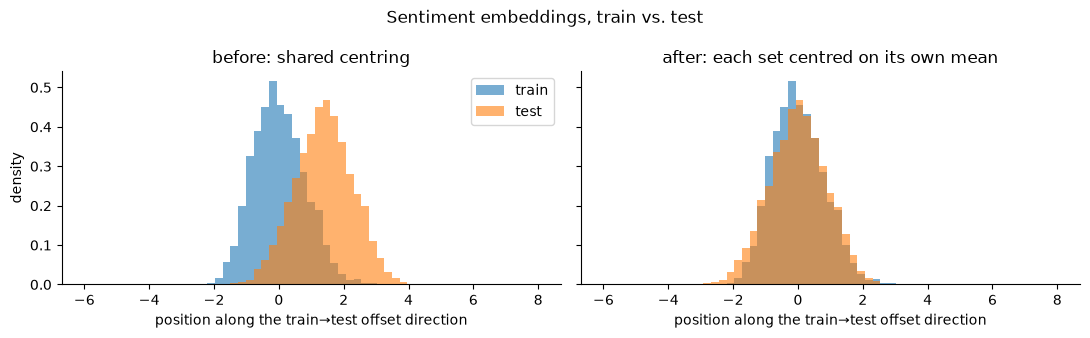

In [6]:
d = T.mean(0) - X.mean(0)
d /= np.linalg.norm(d)
fig, axes = plt.subplots(1, 2, figsize=(11, 3.4), sharey=True)
for ax, (title, a, b) in zip(axes, [("before: shared centring", Xs - X.mean(0), T - X.mean(0)),
                                     ("after: each set centred on its own mean", Xs - X.mean(0), T - T.mean(0))]):
    bins = np.linspace(-6, 8, 60)
    ax.hist(a @ d, bins=bins, alpha=0.6, density=True, label="train")
    ax.hist(b @ d, bins=bins, alpha=0.6, density=True, label="test")
    ax.set(title=title, xlabel="position along the train→test offset direction")
    ax.spines[["top", "right"]].set_visible(False)
axes[0].set_ylabel("density"); axes[0].legend()
fig.suptitle("Sentiment embeddings, train vs. test")
plt.tight_layout(); plt.savefig(FIGURES_DIR / "final_sentiment_shift.png", dpi=130); plt.show()

**Findings:**
* With a shared normalisation, a linear classifier tells training tweets from test tweets with **AUC 0.95**: the two sets occupy visibly different regions (left plot).
* After centring each set on its own mean, the AUC drops to **0.39**. Anything at or below 0.5 means the classifier cannot separate them; it falls below 0.5 here only because each set's mean was removed using all of its rows, which slightly biases the held-out folds.
* So the shift is almost entirely a **constant offset**, about a quarter of the data's typical spread, and not a change in the shape of the data. The right plot shows the two distributions lying on top of each other after re-centring.
* We don't know its cause; plausibly the test tweets were collected or embedded in a different batch. The fix only uses the mean of the unlabelled test features, which is available at prediction time.

In [7]:
names = [SENTIMENT_LABELS[i] for i in range(3)]
_, p_shared = mbs.sentiment_proba(X, y, T)
_, p_recentred = mbs.sentiment_proba(X, y, T, recenter_eval=True)
mix = pd.DataFrame({"shared centring": np.bincount(p_shared.argmax(1), minlength=3) / len(T),
                    "re-centred": np.bincount(p_recentred.argmax(1), minlength=3) / len(T)}, index=names)
print(f"test tweets whose label changes: {np.mean(p_shared.argmax(1) != p_recentred.argmax(1)):.1%}")
mix.style.format("{:.1%}")

test tweets whose label changes: 11.8%


,shared centring,re-centred
Negative,45.1%,37.0%
Neutral,28.3%,30.0%
Positive,26.6%,33.1%


Re-centring changes the predicted label of **11.8%** of test tweets. The skew toward *negative* (45% of predictions with the offset) shrinks to 37%, close to the even split the network predicts on validation. On Kaggle this one step raised the score from 0.639 to **0.649**, the largest single gain of the project.

## 5. What did not work: correcting the sentiment class mix

Before finding the offset, we read the negative-heavy predictions as a sign that the test set simply contains more negative tweets. We estimated the test class mix from the model's own probabilities (EM; Saerens et al., 2002) and re-weighted the predictions accordingly. On validation subsets with a simulated mix the method worked, but on Kaggle it **lowered** the score (0.639 → 0.631). The estimate assumes only the class mix differs, which section 4 shows is false: the offset inflated the negative probabilities, and correcting for a "mix" that wasn't there pushed even more tweets to negative. After re-centring, the same estimator finds an almost even mix:

In [8]:
prior, _ = mbs.em_prior_correction(p_recentred, np.full(3, 1 / 3))
pd.Series(prior, index=names, name="estimated test mix after re-centring").map("{:.1%}".format)

Negative    35.3%
Neutral     30.1%
Positive    34.6%
Name: estimated test mix after re-centring, dtype: str

## 6. Summary

| Step | Kaggle public score |
|---|---|
| k-NN (images) + neural network (sentiment) | 0.627 |
| + blend 20% neural network into the image k-NN | 0.633 |
| + exactly 100 predictions per image class | 0.639 |
| + re-centre the sentiment test embeddings | 0.649 |
| + average 5 sentiment networks (different seeds) | **0.651** |
| *(tried)* correct the sentiment class mix instead of re-centring | 0.631 |

* The largest single gain came from understanding the data rather than from a better model: the sentiment test set is offset by a constant vector, and removing it is worth about 0.01.
* The seed ensemble's +0.002 is within leaderboard noise (2,500 rows per task, so about ±0.7 points from chance alone); on validation it was neutral.
* **Use of test data:** balancing and re-centring use the stated class counts and the mean of the unlabelled test features respectively. No test labels were used, no model was trained on test data, and the public leaderboard was only used to check steps chosen on validation or on the analysis above.